In [2]:
pip install pandas numpy matplotlib scikit-learn nltk wordcloud textblob spacy folium seaborn

  Using cached nltk-3.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached textblob-0.19.0-py3-none-any.whl.metadata (4.4 kB)
  Using cached spacy-3.8.5-cp39-cp39-macosx_11_0_arm64.whl.metadata (27 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached click-8.1.8-py3-none-any.whl.metadata (2.3 kB)
  Using cached spacy_legacy-3.0.12-py2.py3-none-any.whl.metadata (2.8 kB)
  Using cached spacy_loggers-1.0.5-py3-none-any.whl.metadata (23 kB)
  Using cached murmurhash-1.0.12-cp39-cp39-macosx_11_0_arm64.whl.metadata (2.1 kB)
  Using cached cymem-2.0.11-cp39-cp39-macosx_11_0_arm64.whl.metadata (8.5 kB)
  Using cached preshed-3.0.9-cp39-cp39-macosx_11_0_arm64.whl.metadata (2.2 kB)
  Using cached wasabi-1.1.3-py3-none-any.whl.metadata (28 kB)
  Using cached srsly-2.5.1-cp39-cp39-macosx_11_0_arm64.whl.metadata (19 kB)
  Using cached catalogue-2.0.10-py3-none-any.whl.metadata (14 kB)
  Using cached weasel-0.4.1-py3-none-any.whl.metadata (4.6 kB)
  Using cached langc

In [1]:
import pandas as pd
import nltk
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from textblob import TextBlob
import spacy
import folium
import seaborn as sns
import numpy as np
from datetime import datetime
#from gensim import corpora, models



/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/is577/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')  
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /Users/emine2/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/emine2/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/emine2/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [3]:
leo=pd.read_csv('/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/leo_summary_cleaned.csv', encoding='utf-8')
leo

,Summary,WEATHER,OCEAN,LAND,SAFETY,WATER,SNOW,HEALTH,TRANSPORTATION,DIEOFF,...,TRICHINOSIS,BOTULISM,ALASKAPOX,BRUCELLOSIS,CORONAVIRUS,ANISAKID,QFEVER,GIARDIASIS,DIPHTHERIA,MONKEYPOX
0,"On the last Sunday in April, I received a brie...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,The Alaska Migratory Bird Co-Management Counci...,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,"We have a lot of phenological events, but how ...",0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Localized erosion from the spring melt has led...,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,"Ned Rozell’s article explores the vast, geolog...",0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3563,The Northway Mall in northeast Anchorage sits ...,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3564,The risk of a tsunami hitting Anchorage – Alas...,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3565,The Northern Bering Sea showed signs of ecolog...,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3566,There are signs that climate change is depress...,0,0,0,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df = leo.dropna(subset=['Summary'])
df

,Summary,WEATHER,OCEAN,LAND,SAFETY,WATER,SNOW,HEALTH,TRANSPORTATION,DIEOFF,...,TRICHINOSIS,BOTULISM,ALASKAPOX,BRUCELLOSIS,CORONAVIRUS,ANISAKID,QFEVER,GIARDIASIS,DIPHTHERIA,MONKEYPOX
0,"On the last Sunday in April, I received a brie...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,The Alaska Migratory Bird Co-Management Counci...,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
2,"We have a lot of phenological events, but how ...",0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Localized erosion from the spring melt has led...,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,"Ned Rozell’s article explores the vast, geolog...",0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3563,The Northway Mall in northeast Anchorage sits ...,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3564,The risk of a tsunami hitting Anchorage – Alas...,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3565,The Northern Bering Sea showed signs of ecolog...,0,1,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3566,There are signs that climate change is depress...,0,0,0,0,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0


In [8]:
if 'Location' in leo.columns:
    anchorage_count = leo['Location'].str.contains("anchorage", case=False, na=False).sum()
    print(f"Number of entries that include 'Anchorage': {anchorage_count}")

Number of entries that include 'Anchorage': 399


In [9]:
if 'Location' in leo.columns:
    print("\n7. Top 10 Locations")
    print("-----------------")
    print(leo['Location'].value_counts().head(20))


7. Top 10 Locations
-----------------
Location
Anchorage, Alaska, United States      389
Nome, Alaska, United States           148
Alaska, United States                 128
Juneau, Alaska, United States         106
Fairbanks, Alaska, United States       81
Kotzebue, Alaska, United States        74
Whitehorse, Yukon, Canada              71
Bethel, Alaska, United States          71
Utqiaġvik, Alaska, United States       68
Haines, Alaska, United States          55
Unalaska, Alaska, United States        51
Unalakleet, Alaska, United States      48
Kodiak, Alaska, United States          44
Port Heiden, Alaska, United States     40
Sitka, Alaska, United States           40
Homer, Alaska, United States           37
Noatak, Alaska, United States          35
Sand Point, Alaska, United States      35
Shishmaref, Alaska, United States      34
Kivalina, Alaska, United States        33
Name: count, dtype: int64


In [5]:
def preprocess_text(text):
    if pd.isna(text):
        return []
    # Convert non-string values to string
    if not isinstance(text, str):
        text = str(text)
    text = text.lower()  # Lowercase text
    tokens = word_tokenize(text)  # Tokenize into words
    # Remove stopwords and punctuation
    tokens = [word for word in tokens if word not in stopwords.words('english') and word not in string.punctuation]
    return tokens

In [6]:
df['tokens'] = df['Summary'].apply(preprocess_text)


/var/folders/0m/fmdmctq13sj3ylxqpcwqxs1w0000gr/T/ipykernel_33825/419622553.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['tokens'] = df['Summary'].apply(preprocess_text)


In [7]:
# Aggregate all tokens from all summaries
all_tokens = [token for tokens in df['tokens'] for token in tokens]

In [8]:
# Compute token frequency distribution
token_freq = Counter(all_tokens)
print("Most common words:", token_freq.most_common(20))

Most common words: [('alaska', 1036), ('’', 503), ('ice', 306), ('river', 304), ("'s", 297), ('year', 291), ('water', 280), ('sea', 279), ('salmon', 234), ('anchorage', 226), ('snow', 210), ('fish', 210), ('one', 210), ('found', 210), ('said', 197), ('near', 184), ('arctic', 182), ('high', 176), ('winter', 176), ('years', 175)]


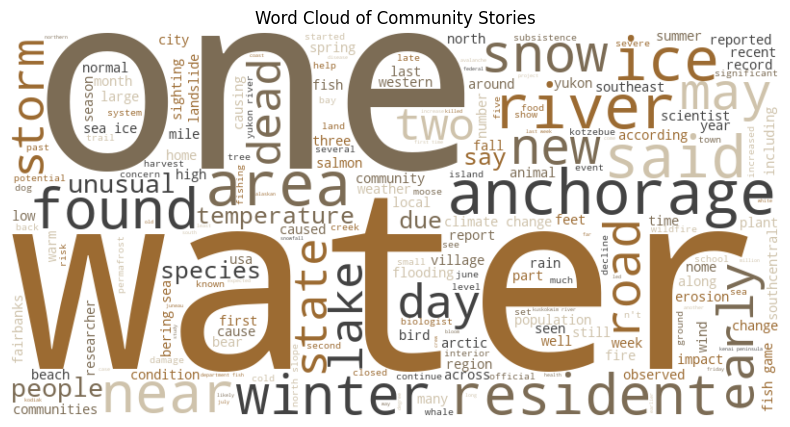

In [9]:
import random
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Remove "alaska" and "year" from all_tokens (case-insensitive)
filtered_tokens = [token for token in all_tokens if token.lower() not in {"alaska", "year","'s"}]
wordcloud_text = " ".join(filtered_tokens)

# Define a custom color function that randomly chooses from a list of colors
def custom_color_func(word, font_size, position, orientation, random_state=None, **kwargs):
    palette = [
        "#434343",  # Dark gray
        "#7C6C55",  # Grayish-brown
        "#9C6B32",  # Brown
        "#CFC3AC"   # Tan
    ]
    return random.choice(palette)

# Create the WordCloud, using the custom color function
wordcloud = WordCloud(
    width=800, 
    height=400,
    background_color='white',
    color_func=custom_color_func  # Apply our custom color function
).generate(wordcloud_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Community Stories")
plt.savefig('word_cloud.png')
plt.show()

## 3. Sentiment Analysis
- Sentiment scoring analysis: to score the sentiment of each story, This can help understand public mood or the emotional tone around events
- Emotion Detection
- Polarity: -1to+1: A score near 0 means the text is neutral, a positive score means the text has a positive sentiment, and a negative score means it has a negative sentiment
- Subjectivity: 0to1: A score closer to 0 means the text is more factual or neutral, whereas a score closer to 1 indicates more personal opinipns, emotions or subjectivity

In [10]:
def get_sentiment(text):
    if pd.isna(text):
        return (0, 0)
    blob = TextBlob(text)
    return blob.sentiment.polarity, blob.sentiment.subjectivity

In [11]:
# Create sentiment columns (polarity and subjectivity) based on the 'Summary' column
df[['polarity', 'subjectivity']] = df['Summary'].apply(lambda x: pd.Series(get_sentiment(x)))
print("Sample sentiment analysis:")
print(df[['Summary', 'polarity', 'subjectivity']].head())

Sample sentiment analysis:
                                             Summary  polarity  subjectivity
0  On the last Sunday in April, I received a brie...  0.100000      0.400000
1  The Alaska Migratory Bird Co-Management Counci... -0.130556      0.302778
2  We have a lot of phenological events, but how ...  0.233333      0.255556
3  Localized erosion from the spring melt has led...  0.000000      0.066667
4  Ned Rozell’s article explores the vast, geolog...  0.150000      0.700000


/var/folders/0m/fmdmctq13sj3ylxqpcwqxs1w0000gr/T/ipykernel_33825/558282876.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['polarity', 'subjectivity']] = df['Summary'].apply(lambda x: pd.Series(get_sentiment(x)))
/var/folders/0m/fmdmctq13sj3ylxqpcwqxs1w0000gr/T/ipykernel_33825/558282876.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['polarity', 'subjectivity']] = df['Summary'].apply(lambda x: pd.Series(get_sentiment(x)))


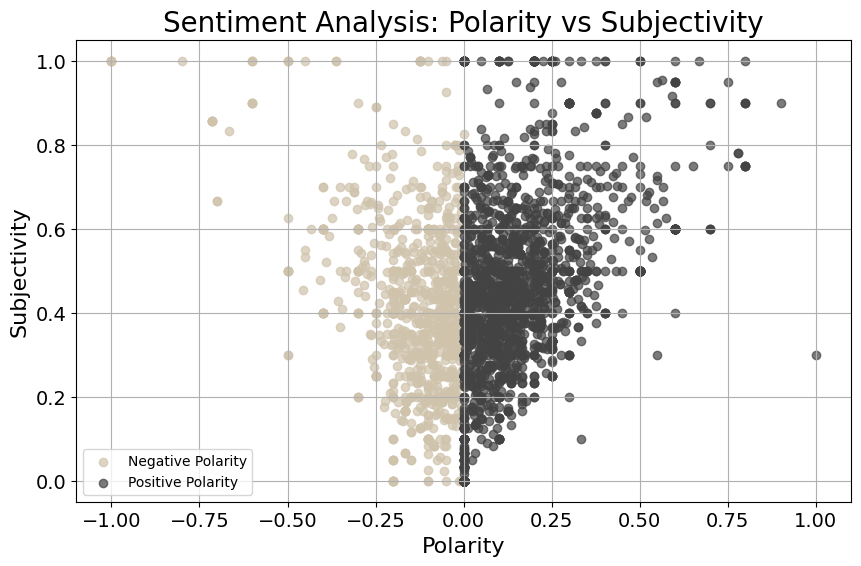

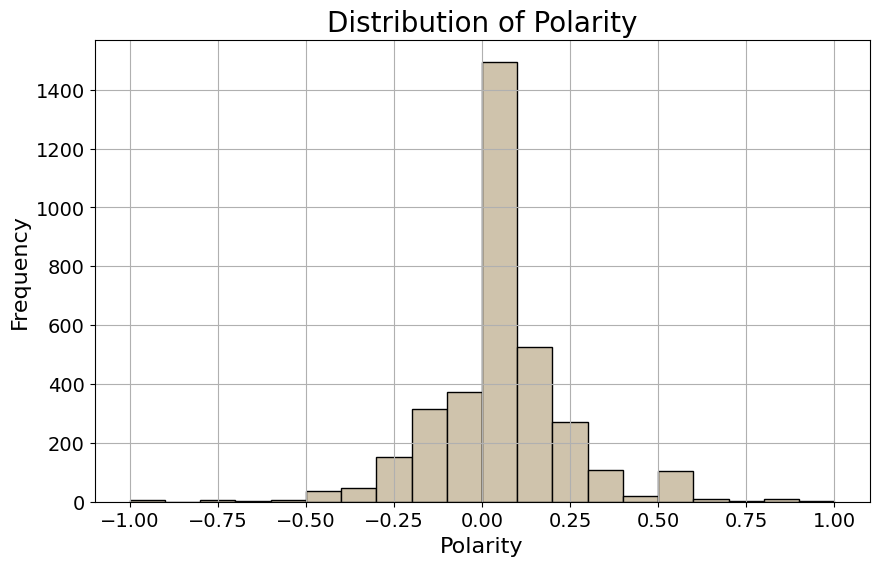

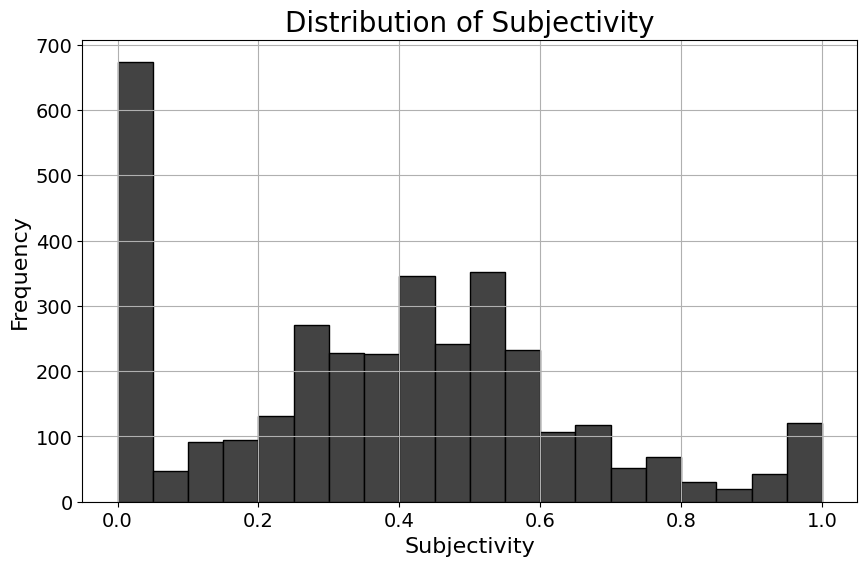

In [12]:
# Scatter plot of polarity vs. subjectivity 
plt.figure(figsize=(10, 6))

# Split the data into negative and non-negative polarity subsets
negative = df[df['polarity'] < 0]
positive = df[df['polarity'] >= 0]

# Plot negative polarity points in color #434343
plt.scatter(negative['polarity'], negative['subjectivity'], color='#CFC3AC', alpha=0.7, label='Negative Polarity')

# Plot non-negative polarity points in color #CFC3AC
plt.scatter(positive['polarity'], positive['subjectivity'], color='#434343', alpha=0.7, label='Positive Polarity')

plt.title('Sentiment Analysis: Polarity vs Subjectivity', fontsize=20)
plt.xlabel('Polarity', fontsize=16)
plt.ylabel('Subjectivity', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True)
plt.legend()

plt.savefig('pol_vs_sub.png')
plt.show()

# Histogram of polarity values using tan color code #CFC3AC with larger fonts
plt.figure(figsize=(10, 6))
plt.hist(df['polarity'], bins=20, color='#CFC3AC', edgecolor='black')
plt.title('Distribution of Polarity', fontsize=20)
plt.xlabel('Polarity', fontsize=16)
plt.ylabel('Frequency', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True)
plt.savefig('pol.png')
plt.show()

# Histogram of subjectivity values using grey color code #434343 with larger fonts
plt.figure(figsize=(10, 6))
plt.hist(df['subjectivity'], bins=20, color='#434343', edgecolor='black')
plt.title('Distribution of Subjectivity', fontsize=20)
plt.xlabel('Subjectivity', fontsize=16)
plt.ylabel('Frequency', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True)
plt.savefig('sub.png')
plt.show()

In [18]:
import folium
import branca.colormap as cm

# Remove rows with missing coordinates
df_clean = df.dropna(subset=['Latitude', 'Longitude'])

# Compute the map center using the mean latitude and longitude from the cleaned data
map_center = [df_clean['Latitude'].mean(), df_clean['Longitude'].mean()]
m = folium.Map(location=map_center, zoom_start=4)

# Define colormaps for polarity and subjectivity
min_pol, max_pol = df_clean['polarity'].min(), df_clean['polarity'].max()
polarity_colormap = cm.LinearColormap(colors=['red', 'white', 'green'],
                                      vmin=min_pol, vmax=max_pol,
                                      caption='Polarity')

min_sub, max_sub = df_clean['subjectivity'].min(), df_clean['subjectivity'].max()
subjectivity_colormap = cm.LinearColormap(colors=['blue', 'white', 'orange'],
                                          vmin=min_sub, vmax=max_sub,
                                          caption='Subjectivity')

# Create a feature group for polarity
polarity_fg = folium.FeatureGroup(name="Polarity")
for idx, row in df_clean.iterrows():
    popup_text = f"Polarity: {row['polarity']:.2f}\nSummary: {str(row['Summary'])[:2000]}"
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        color=polarity_colormap(row['polarity']),
        fill=True,
        fill_color=polarity_colormap(row['polarity']),
        fill_opacity=0.7,
        popup=popup_text
    ).add_to(polarity_fg)

# Create a feature group for subjectivity
subjectivity_fg = folium.FeatureGroup(name="Subjectivity")
for idx, row in df_clean.iterrows():
    popup_text = f"Subjectivity: {row['subjectivity']:.2f}\nSummary: {str(row['Summary'])[:2000]}"
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=5,
        color=subjectivity_colormap(row['subjectivity']),
        fill=True,
        fill_color=subjectivity_colormap(row['subjectivity']),
        fill_opacity=0.7,
        popup=popup_text
    ).add_to(subjectivity_fg)

# Add the feature groups to the map
polarity_fg.add_to(m)
subjectivity_fg.add_to(m)

# Add the colormap legends to the map
m.add_child(polarity_colormap)
m.add_child(subjectivity_colormap)

# Add a layer control to toggle between polarity and subjectivity
folium.LayerControl().add_to(m)

# Save the map to an HTML file
m.save("/Users/emine2/Documents/CLASSES/2025-SPRING/IS-577/project/sentiment_choropleth_map_alaska.html")